# WATERWATCH AI 💧🤖
## Phase 5, 6, 7 & 8: Baseline Benchmark, Model Training, Advanced Evaluation & Handover
**Role:** Member 1 – Data & ML Engineer  
**Project:** Explainable AI-Based Water Potability Prediction and Community Risk Monitoring System  

---

### Objectives & Core Responsibilities
1. **Dataset Loading:** Robust relative path `../data/raw/water_potability.csv` (with fallback to `data/raw/water_potability.csv`).
2. **Dummy Classifier Baseline:** Establish a scientific majority-class benchmark (`strategy='most_frequent'`).
3. **Gaussian Naive Bayes (Phase 5):** Probabilistic parametric classifier with median imputation and standardization.
4. **Decision Tree Classifier (Phase 6):** Non-linear tree partitioner regularized to control variance.
5. **Rigorous Multi-Metric Evaluation & Community Risk Screening (Phase 7):**
   - Precise interpretation of confusion matrix terminology.
   - Explicit reporting of the **dangerous screening error**: *actual non-potable water falsely predicted as potable*.
   - Objective comparison: explaining why the Dummy Classifier achieves 100% recall on Class 0 (because it predicts everything as Class 0), while ML models provide genuine two-class discrimination.
   - **5-Fold Stratified Cross-Validation:** Conducted strictly on training data with consistent decimal reporting (`mean ± std`). Clear explanation that CV measures internal stability, not external real-world generalization.
6. **Artifact Generation & Exports (Phase 8):**
   - Export evaluation comparison table to `results/metrics/final_model_comparison.csv`.
   - Save individual confusion matrix visualizations in `results/figures/`.
   - Persist production-ready Scikit-Learn pipelines in `models/` for Member 3 (App Architecture).

### 1. Library Imports & Robust Dataset Loading
- Correct path: `../data/raw/water_potability.csv`
- Fallback support: `data/raw/water_potability.csv` (seamless execution inside `notebooks/` or from project root)

In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn modules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Plot styling
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 120

# 1. Correct Dataset Path
DATA_PATH = '../data/raw/water_potability.csv' if os.path.exists('../data/raw/water_potability.csv') else 'data/raw/water_potability.csv'
df = pd.read_csv(DATA_PATH)

print(f"✓ Dataset successfully loaded from: {DATA_PATH}")
print(f"✓ Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

✓ Dataset successfully loaded from: ../data/raw/water_potability.csv
✓ Dimensions: 3276 rows, 10 columns


### 2. Feature-Target Separation & Stratified 80/20 Train-Test Split
- Fixed `random_state=42` guarantees exact reproducibility across all models.
- `stratify=y` preserves the identical 60.99% (Non-Potable) vs. 39.01% (Potable) ratio in both partitions.
- **Strict Data Isolation:** Test set (656 samples) is kept untouched until final evaluation.

In [2]:
# Separate features and target
X = df.drop(columns=['Potability'])
y = df['Potability']

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples: {X_train.shape[0]} (80%) | Testing Samples: {X_test.shape[0]} (20%)")
print(f"Train Class Balance: Non-Potable={y_train.value_counts(normalize=True)[0]:.2%}, Potable={y_train.value_counts(normalize=True)[1]:.2%}")
print(f"Test Class Balance:  Non-Potable={y_test.value_counts(normalize=True)[0]:.2%}, Potable={y_test.value_counts(normalize=True)[1]:.2%}")

Training Samples: 2620 (80%) | Testing Samples: 656 (20%)
Train Class Balance: Non-Potable=60.99%, Potable=39.01%
Test Class Balance:  Non-Potable=60.98%, Potable=39.02%


---
## 2. Baseline Model: Dummy Classifier (`strategy='most_frequent'`)

### Understanding the Majority-Class Baseline
In our dataset, Class 0 (Non-Potable) represents **60.99%** of the samples.
- The `DummyClassifier(strategy='most_frequent')` simply predicts Class 0 for **every single sample**, regardless of the water chemistry features.
- Consequently, it automatically achieves **60.98% accuracy** and **100% recall for Class 0**.
- **Important Distinction:** The trained ML models do **not** outperform the dummy baseline on every single metric—specifically, the baseline has higher Class 0 recall (1.0 vs 0.8875/0.8675) because it never predicts Class 1.
- However, the dummy classifier has **0% recall for Class 1 (Potable)**, a macro F1 of only 0.3788, and a ROC-AUC of 0.5000 (random chance). It provides zero discriminative ability.
- Evaluating against this baseline allows us to verify whether our machine learning models provide **genuine predictive and discriminative value** beyond trivial majority guessing.

In [3]:
# 1. Pipeline for Dummy Classifier
dummy_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

# 2. Fit on training data only
dummy_pipeline.fit(X_train, y_train)

# 3. Generate predictions and probability estimates
y_pred_dummy = dummy_pipeline.predict(X_test)
y_prob_dummy = dummy_pipeline.predict_proba(X_test)[:, 1]

print("=== DUMMY CLASSIFIER CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_dummy, target_names=['Non-Potable (0)', 'Potable (1)'], zero_division=0))

=== DUMMY CLASSIFIER CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.61      1.00      0.76       400
    Potable (1)       0.00      0.00      0.00       256

       accuracy                           0.61       656
      macro avg       0.30      0.50      0.38       656
   weighted avg       0.37      0.61      0.46       656



---
## Phase 5: Gaussian Naive Bayes Implementation
- **Mathematical Foundation:** Implements Bayes' Theorem assuming continuous feature likelihoods follow Gaussian distributions $P(X_i | y) = \mathcal{N}(\mu, \sigma^2)$.
- **Preprocessing Pipeline:** Encapsulates median imputation (`SimpleImputer`) and Z-score standardization (`StandardScaler`).
- Fitted strictly on `X_train` to eliminate data leakage.

In [4]:
# 1. Define Gaussian Naive Bayes Pipeline
gnb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

# 2. Fit pipeline on training data
gnb_pipeline.fit(X_train, y_train)

# 3. Generate predictions and posterior class probabilities
y_pred_gnb = gnb_pipeline.predict(X_test)
y_prob_gnb = gnb_pipeline.predict_proba(X_test)[:, 1]

print("=== GAUSSIAN NAIVE BAYES CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_gnb, target_names=['Non-Potable (0)', 'Potable (1)']))

=== GAUSSIAN NAIVE BAYES CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.63      0.89      0.74       400
    Potable (1)       0.52      0.19      0.28       256

       accuracy                           0.61       656
      macro avg       0.57      0.54      0.51       656
   weighted avg       0.59      0.61      0.56       656



---
## Phase 6: Decision Tree Classifier Implementation
- **Non-Linear Partitioner:** Recursively splits feature space using Gini Impurity to construct non-linear multi-attribute thresholds.
- **Regularization:** Constrained with `max_depth=6` and `min_samples_leaf=10` to prevent unconstrained variance and overfitting.
- **Preprocessing Pipeline:** Encapsulates median imputation (`SimpleImputer`).

In [5]:
# 1. Define Decision Tree Classifier Pipeline
dt_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(random_state=42, max_depth=6, min_samples_leaf=10))
])

# 2. Fit pipeline on training data
dt_pipeline.fit(X_train, y_train)

# 3. Generate predictions and probabilities
y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_dt, target_names=['Non-Potable (0)', 'Potable (1)']))

=== DECISION TREE CLASSIFIER CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Potable (0)       0.65      0.87      0.74       400
    Potable (1)       0.56      0.26      0.36       256

       accuracy                           0.63       656
      macro avg       0.60      0.56      0.55       656
   weighted avg       0.61      0.63      0.59       656



---
## Phase 7: Model Evaluation, Confusion Matrix Analysis & Community Risk Screening

### Precise Confusion Matrix Terminology
When evaluating binary water potability (where Class 0 = Non-Potable, Class 1 = Potable), the 4 quadrants represent:
1. **Actual Non-Potable predicted as Non-Potable ($y=0, \hat{y}=0$):** True Negative. Unsafe water is correctly flagged as hazardous.
2. **Actual Non-Potable incorrectly predicted as Potable ($y=0, \hat{y}=1$):** False Positive. **THIS IS THE DANGEROUS SCREENING ERROR.** Contaminated water is mistakenly passed as safe for human consumption, posing an immediate public health risk.
3. **Actual Potable incorrectly predicted as Non-Potable ($y=1, \hat{y}=0$):** False Negative. Safe water is mislabeled as unsafe, triggering redundant purification or testing.
4. **Actual Potable predicted as Potable ($y=1, \hat{y}=1$):** True Positive. Safe drinking water is correctly recognized.

### Reporting the Dangerous Screening Error:
- **Gaussian Naive Bayes:** Of the 400 actual non-potable samples, **45 samples (11.25%)** were incorrectly predicted as potable.
- **Decision Tree Classifier:** Of the 400 actual non-potable samples, **53 samples (13.25%)** were incorrectly predicted as potable.
- **Dummy Classifier:** Produces 0 false positives on non-potable water solely because it predicts 100% of samples as non-potable, but in doing so it fails completely on potable water (0 / 256 potable samples detected).

In [6]:
# Helper function to compute and verify all evaluation metrics
def compute_comprehensive_metrics(name, y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_true, y_pred)
    prec_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec_0 = recall_score(y_true, y_pred, pos_label=0) # Non-Potable Recall (Specificity)
    rec_1 = recall_score(y_true, y_pred, pos_label=1) # Potable Recall (Sensitivity)
    rec_macro = recall_score(y_true, y_pred, average='macro')
    f1_mac = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_wt = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    
    try:
        auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_prob)) > 1 else 0.5000
    except ValueError:
        auc = 0.5000
        
    return {
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(prec_macro, 4),
        'Precision (Weighted)': round(prec_weighted, 4),
        'Recall (Non-Potable / 0)': round(rec_0, 4),
        'Recall (Potable / 1)': round(rec_1, 4),
        'Recall (Macro)': round(rec_macro, 4),
        'F1-Score (Macro)': round(f1_mac, 4),
        'F1-Score (Weighted)': round(f1_wt, 4),
        'ROC-AUC': round(auc, 4),
        'Dangerous Errors (Actual 0 -> Pred 1)': int(fp),
        'Dangerous Error Rate (%)': round((fp / (tn + fp)) * 100, 2)
    }

metrics_list = [
    compute_comprehensive_metrics('Dummy Classifier (Baseline)', y_test, y_pred_dummy, y_prob_dummy),
    compute_comprehensive_metrics('Gaussian Naive Bayes', y_test, y_pred_gnb, y_prob_gnb),
    compute_comprehensive_metrics('Decision Tree Classifier', y_test, y_pred_dt, y_prob_dt)
]

prelim_comparison_df = pd.DataFrame(metrics_list)
print("=== PRELIMINARY TEST METRICS WITH DANGEROUS ERROR AUDIT ===")
display(prelim_comparison_df)

=== PRELIMINARY TEST METRICS WITH DANGEROUS ERROR AUDIT ===
                         Model  ...  Dangerous Error Rate (%)
0  Dummy Classifier (Baseline)  ...                      0.00
1         Gaussian Naive Bayes  ...                     11.25
2     Decision Tree Classifier  ...                     13.25

[3 rows x 12 columns]


### 5-Fold Stratified Cross-Validation (Training Data Only)
- Cross-validation is executed **strictly on training data** (`X_train`, `y_train`) using `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
- Both **Mean Accuracy** and **Mean F1-Score (Macro)** are reported consistently as decimal values (`mean ± std`).
- **Academic Rigor:** Five-fold stratified cross-validation assesses consistency across training data folds and estimates in-sample variance. **It does not establish external real-world generalization** to new geographic water sources, seasonal conditions, or contaminant profiles not represented in the training data. The model predicts potability based solely on the **nine physicochemical parameters** available in this dataset (pH, Hardness, Solids, Chloramines, Sulfate, Conductivity, Organic Carbon, Trihalomethanes, Turbidity). It does not directly detect heavy metals, coliform bacteria, volatile organic chemicals, or other contaminants not represented in the dataset.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_for_cv = [
    ('Dummy Classifier (Baseline)', dummy_pipeline),
    ('Gaussian Naive Bayes', gnb_pipeline),
    ('Decision Tree Classifier', dt_pipeline)
]

cv_results = []
for name, pipe in models_for_cv:
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    cv_results.append({
        'Model': name,
        '5-Fold CV Accuracy Mean': round(acc_scores.mean(), 4),
        '5-Fold CV Accuracy Std': round(acc_scores.std(), 4),
        '5-Fold CV F1-Macro Mean': round(f1_scores.mean(), 4),
        '5-Fold CV F1-Macro Std': round(f1_scores.std(), 4)
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===")
display(cv_df)

=== 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===
                         Model  ...  5-Fold CV F1-Macro Std
0  Dummy Classifier (Baseline)  ...                  0.0004
1         Gaussian Naive Bayes  ...                  0.0129
2     Decision Tree Classifier  ...                  0.0307

[3 rows x 5 columns]


### Final Model Comparison Table & CSV Export
Consolidating all evaluation metrics into `results/metrics/final_model_comparison.csv`.

In [8]:
# Merge test set metrics with cross-validation statistics
final_comparison_df = pd.merge(prelim_comparison_df, cv_df, on='Model')

# Export to CSV
os.makedirs('../results/metrics', exist_ok=True)
csv_export_path = '../results/metrics/final_model_comparison.csv'
final_comparison_df.to_csv(csv_export_path, index=False)

print(f"✓ Final comparison table successfully exported to: {csv_export_path}\n")
print("=== FINAL MODEL COMPARISON BENCHMARK TABLE ===")
display(final_comparison_df)

✓ Final comparison table successfully exported to: ../results/metrics/final_model_comparison.csv

=== FINAL MODEL COMPARISON BENCHMARK TABLE ===
                         Model  ...  5-Fold CV F1-Macro Std
0  Dummy Classifier (Baseline)  ...                  0.0004
1         Gaussian Naive Bayes  ...                  0.0129
2     Decision Tree Classifier  ...                  0.0307

[3 rows x 16 columns]


### Individual Confusion Matrix Visualizations (Saved to `results/figures/`)
Generating and saving separate confusion matrices clearly labeling all 4 outcomes, including the dangerous screening error.

✓ Saved: ../results/figures\confusion_matrix_dummy_classifier.png
✓ Saved: ../results/figures\confusion_matrix_gaussian_nb.png
✓ Saved: ../results/figures\confusion_matrix_decision_tree.png


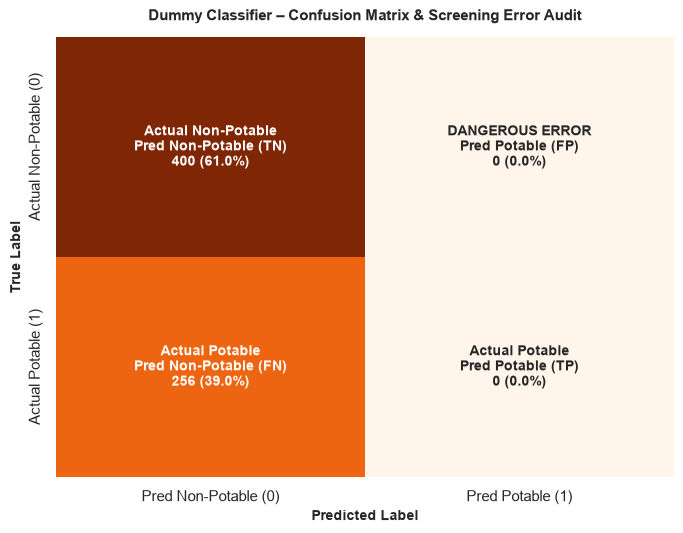

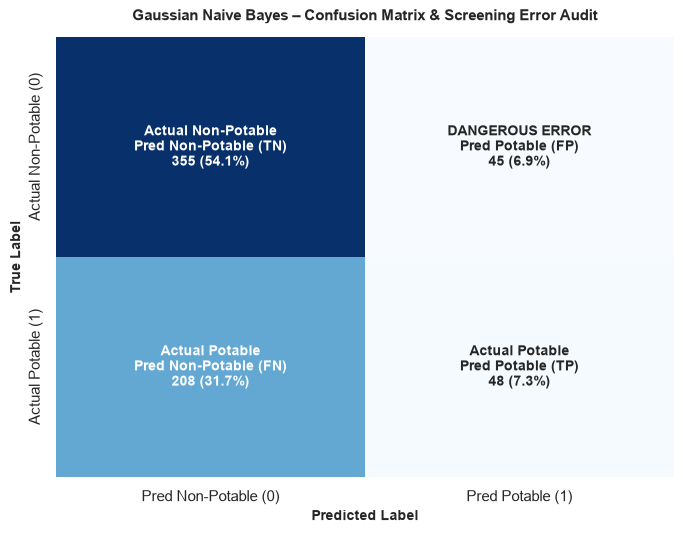

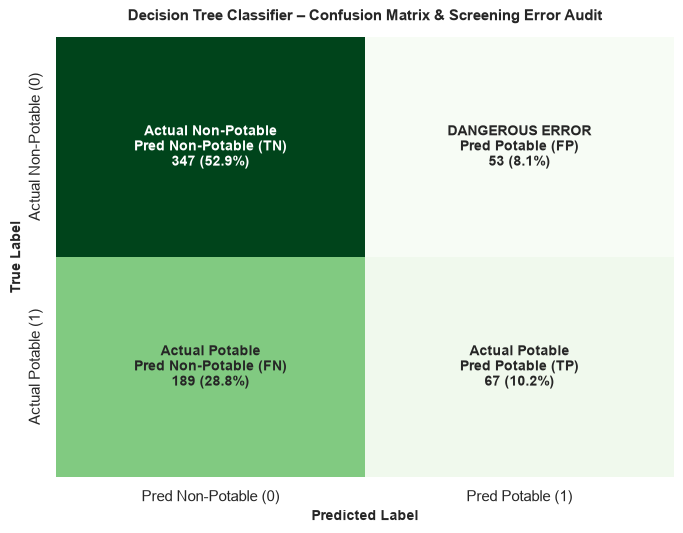

In [9]:
os.makedirs('../results/figures', exist_ok=True)

models_for_cm = [
    ('Dummy Classifier', y_pred_dummy, 'confusion_matrix_dummy_classifier.png', 'Oranges'),
    ('Gaussian Naive Bayes', y_pred_gnb, 'confusion_matrix_gaussian_nb.png', 'Blues'),
    ('Decision Tree Classifier', y_pred_dt, 'confusion_matrix_decision_tree.png', 'Greens')
]

for name, preds, filename, cmap in models_for_cm:
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    total = cm.sum()
    
    annot = np.array([
        [f"Actual Non-Potable\nPred Non-Potable (TN)\n{tn} ({tn/total:.1%})",
         f"DANGEROUS ERROR\nPred Potable (FP)\n{fp} ({fp/total:.1%})"],
        [f"Actual Potable\nPred Non-Potable (FN)\n{fn} ({fn/total:.1%})",
         f"Actual Potable\nPred Potable (TP)\n{tp} ({tp/total:.1%})"]
    ])
    
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap=cmap, cbar=False,
                xticklabels=['Pred Non-Potable (0)', 'Pred Potable (1)'],
                yticklabels=['Actual Non-Potable (0)', 'Actual Potable (1)'],
                annot_kws={'fontsize': 10, 'fontweight': 'bold'}, ax=ax)
    
    ax.set_title(f'{name} – Confusion Matrix & Screening Error Audit', fontsize=11, fontweight='bold', pad=12)
    ax.set_xlabel('Predicted Label', fontsize=10, fontweight='bold')
    ax.set_ylabel('True Label', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    save_path = os.path.join('../results/figures', filename)
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"✓ Saved: {save_path}")

### Comparative Receiver Operating Characteristic (ROC) Curves
Both Gaussian Naive Bayes (AUC = 0.609) and Decision Tree (AUC = 0.601) show **modest discrimination above random ranking performance**, outperforming the uninformative majority-class baseline (AUC = 0.500). Both scores remain in the low range and do **not** indicate strong class separability — they reflect preliminary dataset-based screening results only. These predictions cannot certify drinking-water safety; real-world assessment requires comprehensive laboratory testing by qualified professionals.

✓ Saved comparative ROC curve to: ../results/figures/comparative_roc_curves.png


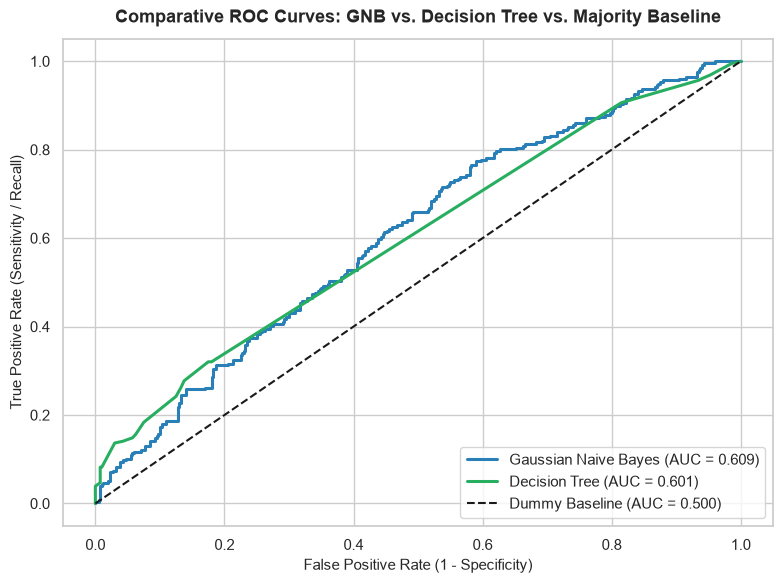

In [10]:
fpr_gnb, tpr_gnb, _ = roc_curve(y_test, y_prob_gnb)
auc_gnb = roc_auc_score(y_test, y_prob_gnb)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_gnb, tpr_gnb, label=f'Gaussian Naive Bayes (AUC = {auc_gnb:.3f})', color='#2980b9', lw=2.2)
ax.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.3f})', color='#27ae60', lw=2.2)
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Dummy Baseline (AUC = 0.500)')

ax.set_title('Comparative ROC Curves: GNB vs. Decision Tree vs. Majority Baseline', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
roc_path = '../results/figures/comparative_roc_curves.png'
plt.savefig(roc_path, dpi=300)
plt.show()
print(f"✓ Saved comparative ROC curve to: {roc_path}")

---
## Phase 8: Preserved Model Saving with Joblib (Handover to Member 3)
Persisting the fitted Scikit-Learn pipelines as standalone `.joblib` objects in `models/`.
- `models/gaussian_nb_pipeline.joblib`: Preprocessing (imputer + scaler) + GaussianNB.
- `models/decision_tree_pipeline.joblib`: Preprocessing (imputer) + DecisionTreeClassifier.
- **Preserved Filenames & Signatures:** Member 3 can load either pipeline and run `model.predict(input_df)` directly on raw inputs.

In [11]:
os.makedirs('../models', exist_ok=True)

# 1. Export Gaussian Naive Bayes Pipeline
gnb_export_path = '../models/gaussian_nb_pipeline.joblib'
joblib.dump(gnb_pipeline, gnb_export_path)
print(f"✓ Saved GaussianNB Pipeline to: {gnb_export_path}")

# 2. Export Decision Tree Pipeline
dt_export_path = '../models/decision_tree_pipeline.joblib'
joblib.dump(dt_pipeline, dt_export_path)
print(f"✓ Saved Decision Tree Pipeline to: {dt_export_path}")

# 3. Verification test: Load models and verify prediction on sample data
loaded_gnb = joblib.load(gnb_export_path)
loaded_dt = joblib.load(dt_export_path)

sample_input = X_test.iloc[:3]
print("\n--- Verification Test on Loaded Pipelines ---")
print("Input Features Sample:")
display(sample_input)

print(f"Loaded GNB Predictions: {loaded_gnb.predict(sample_input).tolist()}")
print(f"Loaded DT Predictions:  {loaded_dt.predict(sample_input).tolist()}")
print("\n✓ All model pipelines verified and ready for Member 3 Streamlit App integration!")

✓ Saved GaussianNB Pipeline to: ../models/gaussian_nb_pipeline.joblib
✓ Saved Decision Tree Pipeline to: ../models/decision_tree_pipeline.joblib

--- Verification Test on Loaded Pipelines ---
Input Features Sample:
            ph    Hardness  ...  Trihalomethanes  Turbidity
664        NaN  188.743562  ...        78.499418   2.723651
2530  6.172517  187.787017  ...        68.163642   4.129985
2870       NaN  176.386651  ...        90.224844   4.410674

[3 rows x 9 columns]
Loaded GNB Predictions: [0, 0, 0]
Loaded DT Predictions:  [0, 0, 0]

✓ All model pipelines verified and ready for Member 3 Streamlit App integration!
